### Import libraries

In [2]:
import re
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data_preprocessing import clean_text
from sklearn.model_selection import train_test_split
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

RANDOM_STATE = 42


### Set project paths and configuration

In [3]:
RAW_DATA_PATH = ROOT / "data" / "raw" / "amazon_mobile_reviews.csv"

PROCESSED_DIR = ROOT / "data" / "processed"
INTERIM_DIR = ROOT / "data" / "interim"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

TEXT_COLUMN = "review_text"
LABEL_COLUMN = "sentiment"

### Load the raw dataset

In [4]:
if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {RAW_DATA_PATH}\n"
        "Please check the dataset filename and folder."
    )

df = pd.read_csv(RAW_DATA_PATH)

In [5]:
df.head()

,review_id,product_name,review_text,rating,sentiment
0,1,120401325X,They look good and stick good! I just don't like the rounded shape because I was always bumping it and Siri kept popping up and it was irritating....,4.0,Positive
1,2,120401325X,These stickers work like the review says they do. They stick on great and they stay on the phone. They are super stylish and I can share them with...,5.0,Positive
2,3,120401325X,These are awesome and make my phone look so stylish! I have only used one so far and have had it on for almost a year! CAN YOU BELIEVE THAT! ONE Y...,5.0,Positive
3,4,120401325X,"Item arrived in great time and was in perfect condition. However, I ordered these buttons because they were a great deal and included a FREE scree...",4.0,Positive
4,5,120401325X,"awesome! stays on, and looks great. can be used on multiple apple products. especially having nails, it helps to have an elevated key.",5.0,Positive


### Check missing values

In [6]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
review_id,0,0.0
product_name,0,0.0
review_text,0,0.0
rating,0,0.0
sentiment,0,0.0


### Validate required columns

In [7]:
required_columns = [TEXT_COLUMN, LABEL_COLUMN]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise KeyError(
        f"Required columns not found: {missing_columns}\n"
        f"Available columns: {df.columns.tolist()}\n"
        "Update TEXT_COLUMN and LABEL_COLUMN in Cell 2."
    )

print("Required columns are available.")

Required columns are available.


### Standardize column names

In [8]:
df = df.rename(columns={
    TEXT_COLUMN: "text",
    LABEL_COLUMN: "sentiment"
})

df["text"] = df["text"].astype("string")
df["sentiment"] = df["sentiment"].astype("string").str.strip()

print("Standardized columns:")
print(df.columns.tolist())

display(df[["text", "sentiment"]].head())

Standardized columns:
['review_id', 'product_name', 'text', 'rating', 'sentiment']


,text,sentiment
0,They look good and stick good! I just don't like the rounded shape because I was always bumping it and Siri kept popping up and it was irritating....,Positive
1,These stickers work like the review says they do. They stick on great and they stay on the phone. They are super stylish and I can share them with...,Positive
2,These are awesome and make my phone look so stylish! I have only used one so far and have had it on for almost a year! CAN YOU BELIEVE THAT! ONE Y...,Positive
3,"Item arrived in great time and was in perfect condition. However, I ordered these buttons because they were a great deal and included a FREE scree...",Positive
4,"awesome! stays on, and looks great. can be used on multiple apple products. especially having nails, it helps to have an elevated key.",Positive


### Check sentiment labels

In [9]:
print("Unique sentiment labels:")
print(df["sentiment"].value_counts(dropna=False))

print("\nNumber of unique labels:")
print(df["sentiment"].nunique())

Unique sentiment labels:
sentiment
Positive    14353
Negative     3358
Neutral      2289
Name: count, dtype: int64[pyarrow]

Number of unique labels:
3


### Clean sentiment labels

In [10]:
df["sentiment"] = df["sentiment"].str.strip().str.lower()

label_mapping = {
    "positive": "positive",
    "pos": "positive",
    "negative": "negative",
    "neg": "negative",
    "neutral": "neutral",
    "neu": "neutral"
}

df["sentiment"] = df["sentiment"].replace(label_mapping)

VALID_LABELS = ["positive", "negative", "neutral"]

invalid_labels = ~df["sentiment"].isin(VALID_LABELS)

print("Invalid or missing labels:", invalid_labels.sum())

df = df.loc[~invalid_labels].copy()

print("\nSentiment labels after cleaning:")
print(df["sentiment"].value_counts())

Invalid or missing labels: 0

Sentiment labels after cleaning:
sentiment
positive    14353
negative     3358
neutral      2289
Name: count, dtype: int64[pyarrow]


### Clean text data

In [11]:
df["clean_text"] = df["text"].apply(clean_text)

print("Text cleaning completed!")
display(df[["text", "clean_text", "sentiment"]].head(5))


Text cleaning completed!


,text,clean_text,sentiment
0,They look good and stick good! I just don't like the rounded shape because I was always bumping it and Siri kept popping up and it was irritating....,they look good and stick good! i just don't like the rounded shape because i was always bumping it and siri kept popping up and it was irritating....,positive
1,These stickers work like the review says they do. They stick on great and they stay on the phone. They are super stylish and I can share them with...,these stickers work like the review says they do. they stick on great and they stay on the phone. they are super stylish and i can share them with...,positive
2,These are awesome and make my phone look so stylish! I have only used one so far and have had it on for almost a year! CAN YOU BELIEVE THAT! ONE Y...,these are awesome and make my phone look so stylish! i have only used one so far and have had it on for almost a year! can you believe that! one y...,positive
3,"Item arrived in great time and was in perfect condition. However, I ordered these buttons because they were a great deal and included a FREE scree...","item arrived in great time and was in perfect condition. however, i ordered these buttons because they were a great deal and included a free scree...",positive
4,"awesome! stays on, and looks great. can be used on multiple apple products. especially having nails, it helps to have an elevated key.","awesome! stays on, and looks great. can be used on multiple apple products. especially having nails, it helps to have an elevated key.",positive


### Check duplicate reviews

In [12]:
print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate text-label pairs:",
    df.duplicated(subset=["clean_text", "sentiment"]).sum()
)

label_counts_per_text = df.groupby("clean_text")["sentiment"].nunique()

conflicting_texts = label_counts_per_text[
    label_counts_per_text > 1
]

print(
    "Reviews with conflicting sentiment labels:",
    len(conflicting_texts)
)

Exact duplicate rows: 0
Duplicate text-label pairs: 11
Reviews with conflicting sentiment labels: 0


### Remove duplicate records

In [13]:
before = len(df)

df = df.drop_duplicates(
    subset=["clean_text", "sentiment"]
).reset_index(drop=True)

print("Dataset shape:", df.shape)

Dataset shape: (19989, 6)


### Analyze sentiment distribution

In [14]:
sentiment_counts = df["sentiment"].value_counts()

display(
    sentiment_counts.rename("Count").to_frame()
)

,Count
sentiment,
positive,14344
negative,3358
neutral,2287


### Visualize sentiment distribution

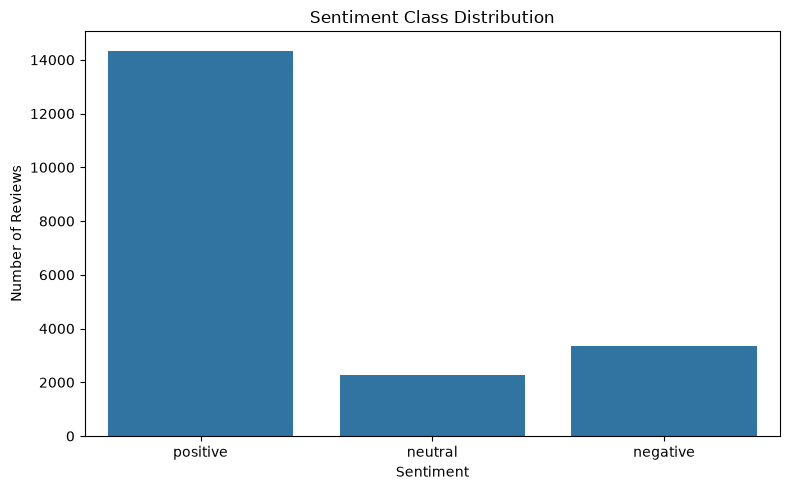

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment",
    order=["positive", "neutral", "negative"]
)

plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

### Analyze review lengths

In [16]:
df["word_count"] = df["clean_text"].str.split().str.len()
df["character_count"] = df["clean_text"].str.len()

display(
    df[["word_count", "character_count"]].describe().T
)

,count,mean,std,min,25%,50%,75%,max
word_count,19989.0,102.758067,159.704602,1.0,29.0,52.0,114.0,3991.0
character_count,19989.0,549.093551,876.682749,1.0,149.0,270.0,599.0,21630.0


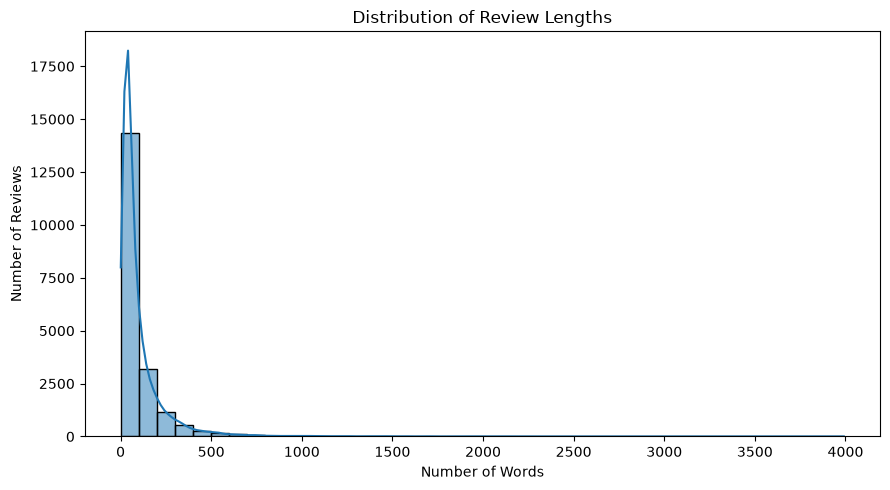

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=40,
    kde=True
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

### Check the cleaned dataset

In [18]:
print("Final cleaned dataset shape:", df.shape)

print("\nMissing values:")
print(df[["text", "clean_text", "sentiment"]].isna().sum())

print("\nEmpty cleaned reviews:")
print(df["clean_text"].str.strip().eq("").sum())

print("\nDuplicate text-label pairs:")
print(df.duplicated(
    subset=["clean_text", "sentiment"]
).sum())

print("\nFinal sentiment distribution:")
print(df["sentiment"].value_counts())

Final cleaned dataset shape: (19989, 8)

Missing values:
text          0
clean_text    0
sentiment     0
dtype: int64

Empty cleaned reviews:
0

Duplicate text-label pairs:
0

Final sentiment distribution:
sentiment
positive    14344
negative     3358
neutral      2287
Name: count, dtype: int64[pyarrow]


### Prepare data for splitting

In [19]:
model_df = df[
    ["text", "clean_text", "sentiment"]
].copy()

model_df = model_df.reset_index(drop=True)

print("Data ready for splitting:", model_df.shape)

display(model_df.head())

Data ready for splitting: (19989, 3)


,text,clean_text,sentiment
0,They look good and stick good! I just don't like the rounded shape because I was always bumping it and Siri kept popping up and it was irritating....,they look good and stick good! i just don't like the rounded shape because i was always bumping it and siri kept popping up and it was irritating....,positive
1,These stickers work like the review says they do. They stick on great and they stay on the phone. They are super stylish and I can share them with...,these stickers work like the review says they do. they stick on great and they stay on the phone. they are super stylish and i can share them with...,positive
2,These are awesome and make my phone look so stylish! I have only used one so far and have had it on for almost a year! CAN YOU BELIEVE THAT! ONE Y...,these are awesome and make my phone look so stylish! i have only used one so far and have had it on for almost a year! can you believe that! one y...,positive
3,"Item arrived in great time and was in perfect condition. However, I ordered these buttons because they were a great deal and included a FREE scree...","item arrived in great time and was in perfect condition. however, i ordered these buttons because they were a great deal and included a free scree...",positive
4,"awesome! stays on, and looks great. can be used on multiple apple products. especially having nails, it helps to have an elevated key.","awesome! stays on, and looks great. can be used on multiple apple products. especially having nails, it helps to have an elevated key.",positive


### Split into training, validation, and testing sets

In [20]:
train_df, temp_df = train_test_split(
    model_df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=model_df["sentiment"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_df["sentiment"]
)

print("Training dataset:", train_df.shape)
print("Validation dataset:", val_df.shape)
print("Testing dataset:", test_df.shape)

train_df.to_csv(PROCESSED_DIR / "train.csv", index=False, encoding="utf-8")
val_df.to_csv(PROCESSED_DIR / "validation.csv", index=False, encoding="utf-8")
test_df.to_csv(PROCESSED_DIR / "test.csv", index=False, encoding="utf-8")

print("Saved train, validation, and test splits to:", PROCESSED_DIR)


Training dataset: (15991, 3)
Validation dataset: (1999, 3)
Testing dataset: (1999, 3)
Saved train, validation, and test splits to: d:\My_Project\Analyse\mobile-review-sentiment-analysis\data\processed


### Compare sentiment distribution across splits

,Train,Validation,Test
sentiment,,,
positive,71.76,71.79,71.74
negative,16.8,16.81,16.81
neutral,11.44,11.41,11.46


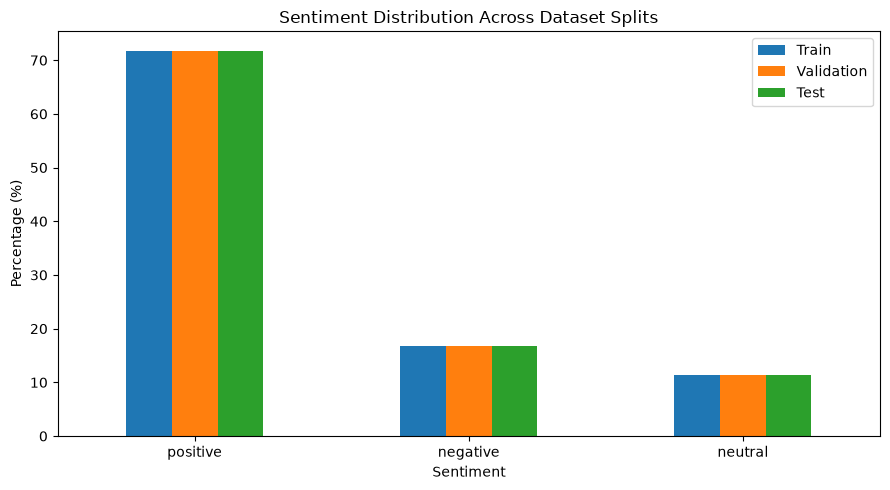

In [21]:
distribution = pd.concat(
    [
        train_df["sentiment"].value_counts(normalize=True).rename("Train"),
        val_df["sentiment"].value_counts(normalize=True).rename("Validation"),
        test_df["sentiment"].value_counts(normalize=True).rename("Test")
    ],
    axis=1
).fillna(0) * 100

distribution = distribution.round(2)

display(distribution)

distribution.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Sentiment Distribution Across Dataset Splits")
plt.xlabel("Sentiment")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Check for data leakage

In [22]:
train_texts = set(train_df["clean_text"])
val_texts = set(val_df["clean_text"])
test_texts = set(test_df["clean_text"])

print("Train-validation overlap:", len(train_texts & val_texts))
print("Train-test overlap:", len(train_texts & test_texts))
print("Validation-test overlap:", len(val_texts & test_texts))

assert train_texts.isdisjoint(val_texts)
assert train_texts.isdisjoint(test_texts)
assert val_texts.isdisjoint(test_texts)

print("\nNo duplicate cleaned reviews across splits.")

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

No duplicate cleaned reviews across splits.


### Save the cleaned dataset

In [23]:
cleaned_path = PROCESSED_DIR / "cleaned_reviews.csv"

df.to_csv(
    cleaned_path,
    index=False,
    encoding="utf-8"
)